# Cable model simulation

In this notebook, we will investigate the cable model using the NEURON simulation platform.


In [1]:
%%capture
!pip install neuron

In [2]:
from neuron import n
import matplotlib.pyplot as plt
n.load_file('stdrun.hoc');

# Create a dendrite with only passive properties
Creates a single section called "dendrite" (stored in  variable `den`). Set its dimensions to 10 cm (100000um) in length (`L`) and 25 um in diameter (`diam`). For fine spatial resolution of the simulation, we ask NEURON to put 1001 segments (`nseg`) onto the dendrite.

```
from neuron.units import cm, um
den = n.Section(name="dendrite");
den.L = 10 * cm
den.diam = 25 * um
den.nseg = 1001
```

We then put in the passive neuronal properties on the whole dendrite.
```
den.insert("pas")
```

Finally, we introduce an "electrode" for current clamp (`IClamp`) in the middle of the dendrite `den(0.5)`, so that we can observe the effect of injecting a current.

```
stim = n.IClamp(den(0.5))    
```

In [ ]:
# @title
# import necessary units from the NEURON module
from neuron.units import cm, um

# create a dendritic section
den = n.Section(name="dendrite");

# set the length, diameter, and number of segments of the dendrite
den.L = 10 * cm
den.diam = 25 * um
den.nseg = 1001

# insert passive properties into the dendrite
den.insert("pas");

# current clamp at the middle of the dendrite
stim = n.IClamp(den(0.5))       

# Define things to record
Here we define what we want to observe. `i_vec` is our injected current, `v_vec_list` stores the voltage at different locations along the dendrite, `t_vec` stores the corresponding time (in ms) for `i_vec` and items in `v_vec_list`. 

These are "vectors" which in this case just means each is a series of numbers.

In [ ]:
i_vec = n.Vector().record(stim._ref_i)
t_vec = n.Vector().record(n._ref_t)

import numpy as np
v_vec_list = {}
loc_list = {}
for i_loc, location in enumerate(np.linspace(0,1,den.nseg)):
    v_vec_list[i_loc] = n.Vector().record(den(location)._ref_v)
    loc_list[i_loc] = location

# Run stimulation with a simple current step
The following code setup the experimental properties: stimulation, duration of the stimulation and initializes the membrane potential of the dendrite. The last line `n.run();` tells NEURON to run the simulation. Results are automatically stored in the vectors defined above (`i_vec`, `t_vec`, etc.).

In [ ]:
stim.delay = 1 # ms; delay before the current pulse starts
stim.dur = 5   # ms; duration of the current pulse
stim.amp = 100 # nA; amplitude of the current pulse

n.tstop = 15 # ms; how long the simulation runs
n.v_init = -70 #mV; initial membrane potential
n.run(); # run the simulation

# Plotting the results
We first define a couple of functions to help us plot the results.
- The first function `plot_V_vs_T()` plots the injected current, the voltage at different positions as a function of time. It also normalizes the voltage traces to their maximum to show the shape of the signal.
- The second function `plot_V_vs_X()` plots the voltage as a function of position at multiple time points.
- The third function `create_animation_V_vs_X` make a animation from the V_vs_X plots.

In [ ]:
# @title define the function plot_V_vs_T()
def plot_V_vs_T(loc_to_plot_um = np.array([0,1000,2000,3000,4000,5000,6000,7000,8000,9000,10000]),
                t_range = None):
    # # Map the physical locations (0 to 5000 um, relative to center) to segment indexes.

    # The dendrite is modeled from 0 to 1, with center at 0.5.
    # Physical location x = 0.5 * den.L + loc_to_plot_um
    stim_loc = stim.get_loc()
    segment_positions = stim_loc + (loc_to_plot_um / den.L)
    i_loc_to_plot = np.round(segment_positions * (den.nseg - 1)).astype(int)
    n_loc = len(i_loc_to_plot)

    # define delay
    t_delay = stim.delay
    if t_range is None:
        t_range = (t_vec[0]-t_delay,t_vec[-1]-t_delay)

    # find reversal potential of passive properties `pas`
    V_rev =  den(0.5).pas.e # mV

    # Collect v_vec at different locations
    v_matrix = np.array([v_vec_list[i] for i in sorted(v_vec_list.keys())]).T

    fig, (ax_i,ax_v,ax_norm) = plt.subplots(3,1,figsize=(6, 8))

    # Get magma colormap values for each target time point
    colors = plt.cm.viridis_r(np.linspace(0, 1, n_loc))

    ax_i.plot(t_vec-t_delay, i_vec, label=f'current')
    ax_i.set_title('Injected Current')
    ax_i.set_xlabel('Time (ms)')
    ax_i.set_ylabel('Current Amplitude (nA)')
    ax_i.set_xlim(t_range)


    for i_curve, i_loc in enumerate(i_loc_to_plot):
        ax_v.plot(t_vec-t_delay, v_vec_list[i_loc],color=colors[i_curve],label=f'{(loc_list[i_loc]-0.5)*den.L/1000:.0f} mm')
    ax_v.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax_v.set_title('Voltage profile')
    ax_v.set_ylabel('Membrane Potential (mV)')
    ax_v.set_xlabel('Time (ms)')
    ax_v.set_xlim(t_range)
    for i_curve, i_loc in enumerate(i_loc_to_plot):
        max_dV, min_dV = max(v_vec_list[i_loc] - V_rev), min(v_vec_list[i_loc] - V_rev)
        if max_dV > -min_dV:
            max_dev_V = max_dV
        elif min_dV < 0:
            max_dev_V = -min_dV
        else:
            max_dev_V = 1
        ax_norm.plot(t_vec-t_delay, (v_vec_list[i_loc]-V_rev)/max_dev_V,color=colors[i_curve])
    ax_norm.set_title('Normalized voltage profile')
    ax_norm.set_ylabel('Normalized Voltage')
    ax_norm.set_xlabel('Time (ms)')
    ax_norm.set_xlim(t_range)

    plt.tight_layout()
    plt.show()

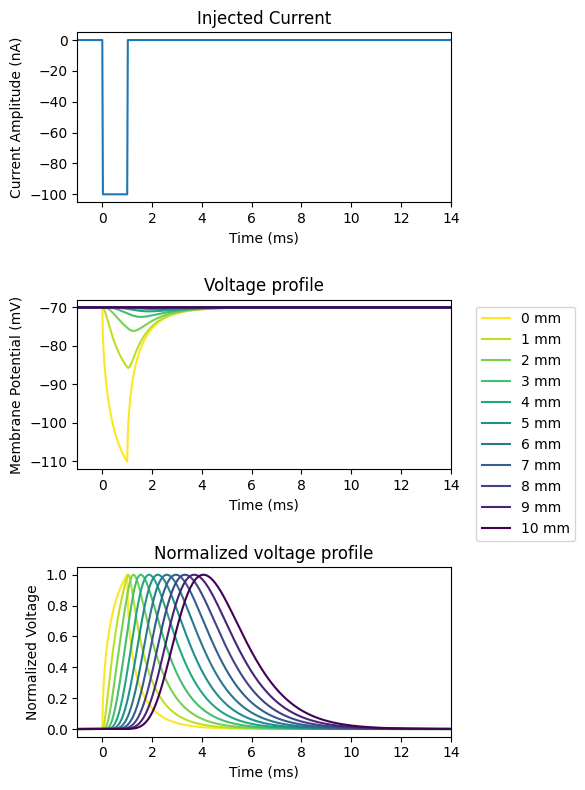

In [42]:
plot_V_vs_T()

In [ ]:
# @title Interactive stimulus control
# Interactive: use the sliders to change the stimulus amplitude and duration
import ipywidgets as widgets
from IPython.display import display, clear_output

amp_slider = widgets.FloatSlider(value=100, min=0, max=500, step=10, description='amp (nA)',
                                 continuous_update=False, style={'description_width': 'initial'})
dur_slider = widgets.FloatSlider(value=5, min=0.1, max=10, step=0.1, description='dur (ms)',
                                 continuous_update=False, style={'description_width': 'initial'})
out = widgets.Output()

def run_and_plot(amp, dur):
    stim.delay = 1
    stim.amp = amp
    stim.dur = dur
    n.tstop = 15
    n.v_init = -70
    n.run()
    with out:
        clear_output(wait=True)
        plot_V_vs_T()
        plt.show()

def on_change(change):
    run_and_plot(amp_slider.value, dur_slider.value)

amp_slider.observe(on_change, names='value')
dur_slider.observe(on_change, names='value')

display(widgets.VBox([amp_slider, dur_slider, out]))
run_and_plot(amp_slider.value, dur_slider.value)

In [8]:
# @title define the function plot_V_vs_X()
def plot_V_vs_X(t_to_plot = None,
                x_range = None):

    # Collect v_vec at different locations
    v_matrix = np.array([v_vec_list[i] for i in sorted(v_vec_list.keys())]).T

    stim_loc = stim.get_loc()

    num_locations = v_matrix.shape[1]
    x_coords = np.linspace(0, den.L, num_locations)- stim_loc*den.L # Distance along the dendrite in micrometers

    if t_to_plot is None:
        t_end = t_vec[-1]
        t_to_plot= np.linspace(0,t_end,7)

    plt.figure(figsize=(10, 6))

    # Get magma colormap values for each target time point
    colors = plt.cm.viridis(np.linspace(0, 1, len(t_to_plot)))

    for i, t_target in enumerate(t_to_plot):
        # Find the index of the closest recorded time step to our target time
        idx = (np.abs(t_vec - t_target)).argmin()
        actual_time = t_vec[idx]

        # Plot voltage along the dendrite length with magma color progression
        plt.plot(x_coords, v_matrix[idx, :], label=f't = {actual_time:.2f} ms', color=colors[i])

    plt.title('Voltage Profile Along the Dendrite at Different Time Points')
    plt.xlabel('Distance from stimulation site (µm)')
    plt.ylabel('Membrane Potential (mV)')
    plt.grid(True, linestyle='--', alpha=0.6)
    # plt.xlim(0, den.L)
    plt.legend()
    plt.show()

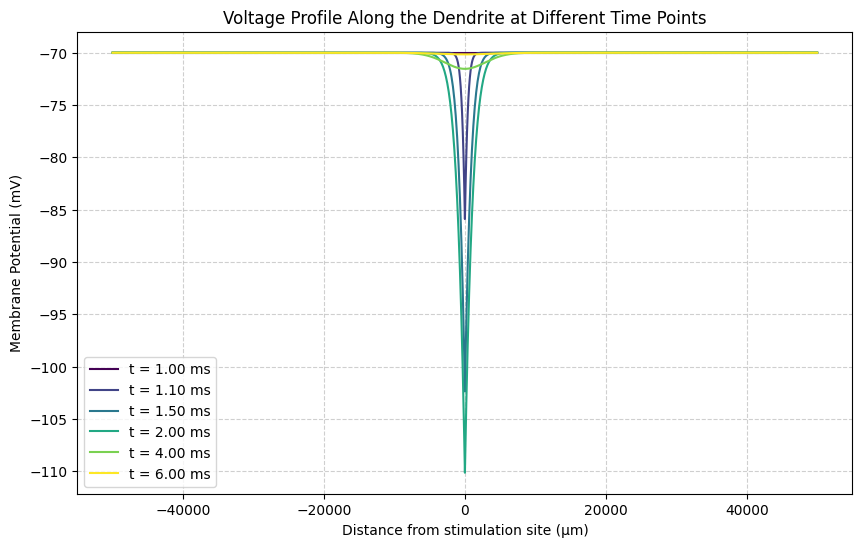

In [43]:
plot_V_vs_X(t_to_plot=[1,1.1,1.5,2,4,6])

In [49]:
# @title define function create_animation_V_vs_X()
def create_animation_V_vs_X(xrange=None,figsize=(10, 6)):
  from matplotlib.animation import FuncAnimation
  from IPython.display import HTML

  v_matrix = np.array([v_vec_list[i] for i in sorted(v_vec_list.keys())]).T

  stim_loc = stim.get_loc()
  num_locations = v_matrix.shape[1]
  x_coords = np.linspace(0, den.L, num_locations)- stim_loc*den.L # Distance along the dendrite in micrometers

  if xrange is None:
      xrange = (x_coords[0],x_coords[-1])

  # Set up the figure, axes, and plot element
  fig, ax = plt.subplots(figsize=figsize)
  ax.set_xlim(x_coords[0], x_coords[-1])
  # Find min and max voltage to bound the y-axis
  all_v_values = v_matrix.flatten()
  ax.set_ylim(all_v_values.min() - 5, all_v_values.max() + 5)
  ax.set_xlim(xrange)

  line, = ax.plot([], [], lw=2, color='darkblue')
  time_text = ax.text(0.05, 0.9, '', transform=ax.transAxes, fontsize=12)

  ax.set_title('Dynamic Voltage Profile Along Dendrite Over Time')
  ax.set_xlabel('Distance from stimulation site (µm)')
  ax.set_ylabel('Membrane Potential (mV)')
  ax.grid(True, linestyle='--', alpha=0.6)

  # Initialization function
  def init():
      line.set_data([], [])
      time_text.set_text('')
      return line, time_text

  # Animation function: called sequentially
  def animate(i):
      y_data = v_matrix[i, :]
      line.set_data(x_coords, y_data)
      time_text.set_text(f'Time = {t_vec[i]:.2f} ms')
      return line, time_text

  # Create animation with a subset of frames to speed up rendering
  step = max(1, len(t_vec) // 150)  # Aim for ~150 frames
  frames = range(0, len(t_vec), step)

  anim = FuncAnimation(fig, animate, init_func=init,
                                frames=frames, interval=50, blit=True)

  plt.close(fig) # Avoid displaying a static plot of the last frame
  return HTML(anim.to_jshtml())

In [44]:
create_animation_V_vs_X(figsize=(10,5)) # this takes a few seconds to run

# Run stimulation with a different step

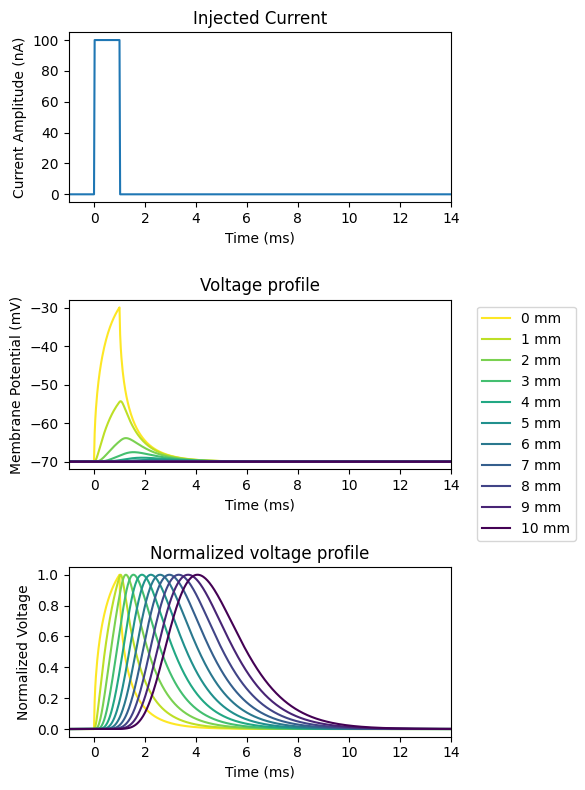

In [45]:
stim.delay = 1
stim.dur = 1
stim.amp = 100

n.tstop = 15
n.v_init = -70 #mV
n.run();

plot_V_vs_T()
# plot_V_vs_X()
create_animation_V_vs_X(figsize=(10,5)) # this takes a few seconds to run

## Simulation with negative current injection

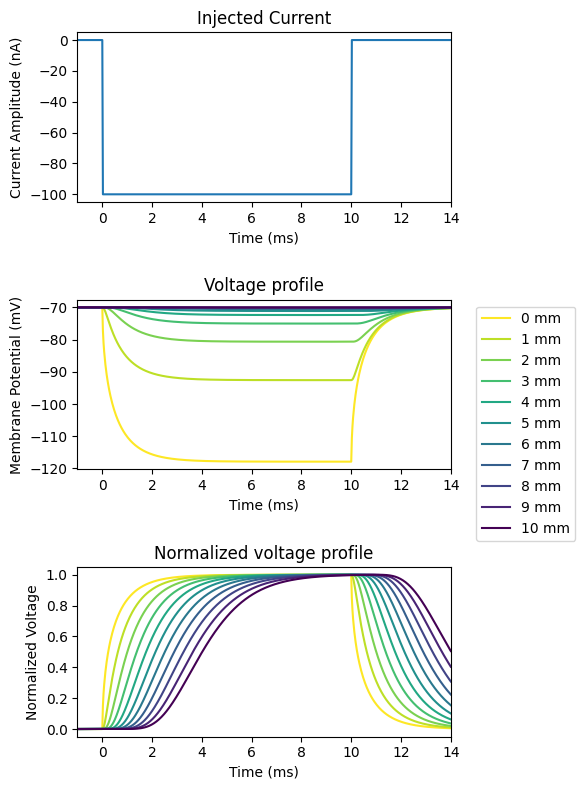

In [51]:
stim.delay = 1
stim.dur = 10
stim.amp = -100

n.tstop = 15
n.v_init = -70 #mV
n.run();

plot_V_vs_T()
# plot_V_vs_X()
create_animation_V_vs_X(figsize=(10,5)) # this takes a few seconds to run

# Run simuation with arbitrary waveform

We do not need to limit the current injection as step functions. Here we demonstrate how to create an arbitrary waveform as the current. The current is now a oscillating sine wave that decays over time.

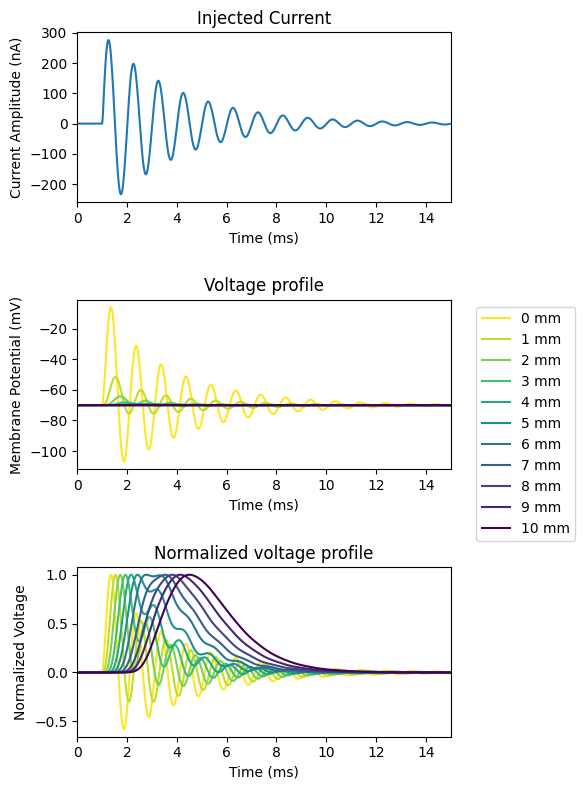

In [52]:
# 1. Create the arbitrary current waveform in NumPy
t_arr = np.linspace(0, 15, 1201)

# Let's design a modulated sine wave as our arbitrary waveform
# Waveform starts after 1 ms, oscillates at 1 kHz, and decays
raw_waveform = 300 * np.sin(2 * np.pi * 1.0 * (t_arr - 1)) * np.exp(-(t_arr - 1) / 3)
raw_waveform[t_arr < 1.0] = 0.0  # Keep it 0 before the stimulus delay

# 2. Convert the NumPy arrays to static NEURON Vectors for playback
stim_amp_vec = n.Vector(raw_waveform)
stim_time_vec = n.Vector(t_arr)

# 3. Use Vector.play to dynamically drive stim.amp with our custom waveform over time
# We play stim_amp_vec into stim._ref_amp, using stim_time_vec as the static time map with interpolation
stim.amp = 0; # clear amp
stim.delay = 0;
stim.dur = 15;
stim_amp_vec.play(stim._ref_amp, stim_time_vec,True)

# 4. Initialize and Run the simulation
n.tstop = 15
n.v_init = -70
n.run()

# To stop stim_amp_vec from driving stim.amp, call play_remove()
stim_amp_vec.play_remove()

plot_V_vs_T()

In [53]:
create_animation_V_vs_X(figsize=(10,5),xrange=(-5000,5000)) # this takes a few seconds to run